# FinSight — Exploratory Data Analysis (Day 2)

**Purpose (guidelines §II.A):** understand the data before modelling — coverage,
distributions, patterns, missing values and outliers — and record the findings
in `docs/DATA_CARD.md`.

**Input:** the DVC-versioned snapshot `data/raw/{prices,news}.parquet` produced by the
`export` stage, plus `reports/data_quality.json` from `validate`. Run `dvc repro` first.
Figures are written to `reports/figures/` (tracked with Git LFS).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

prices = pd.read_parquet(ROOT / "data/raw/prices.parquet")
news = pd.read_parquet(ROOT / "data/raw/news.parquet")
quality = json.loads((ROOT / "reports/data_quality.json").read_text())
prices["date"] = pd.to_datetime(prices["date"])
has_all_adj = prices.groupby("ticker")["adj_close"].transform(lambda s: s.notna().all())
prices["price"] = prices["adj_close"].where(has_all_adj, prices["close"])
prices = prices.sort_values(["ticker", "date"])
prices["log_return"] = prices.groupby("ticker")["price"].transform(lambda s: np.log(s / s.shift()))
TICKERS = sorted(prices["ticker"].unique())
print(f"{len(prices):,} price rows, {len(news):,} articles, {len(TICKERS)} tickers")
print("Data-quality status:", quality["status"], quality["summary"])

2,492 price rows, 10,756 articles, 10 tickers
Data-quality status: pass {'checks': 21, 'errors': 0, 'passed': 19, 'warnings': 2}


## 1. Coverage and missing trading days

In [2]:
coverage = pd.DataFrame(quality["per_ticker"]).T[[
    "rows", "first_date", "last_date", "expected_trading_days", "missing_trading_days",
    "sessions_behind", "price_field", "sources", "news_articles", "news_thin_weeks"]]
coverage

,rows,first_date,last_date,expected_trading_days,missing_trading_days,sessions_behind,price_field,sources,news_articles,news_thin_weeks
AAPL,250,2025-10-21,2026-10-21,252,2,0,adj_close,[marketstack],1079,0
AMZN,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1081,0
GOOGL,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1081,0
JPM,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1075,0
META,250,2025-10-21,2026-10-21,252,2,0,close,"[marketstack, yfinance]",1081,0
MSFT,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1082,0
NVDA,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1087,0
TSLA,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1083,0
V,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1049,0
WMT,249,2025-10-21,2026-10-21,252,3,0,adj_close,[marketstack],1058,0


In [3]:
missing = {t: v["missing_dates"] for t, v in quality["per_ticker"].items() if v.get("missing_dates")}
print("Trading days absent per ticker (forward-filled by the Spark ETL if <= etl.max_ffill_days):")
for ticker, dates in missing.items():
    print(f"  {ticker:<6} {', '.join(dates)}")
if not missing:
    print("  none")

Trading days absent per ticker (forward-filled by the Spark ETL if <= etl.max_ffill_days):
  AAPL   2026-06-09, 2026-06-10
  AMZN   2026-06-09, 2026-06-10, 2026-06-15
  GOOGL  2026-06-09, 2026-06-10, 2026-06-15
  JPM    2026-06-09, 2026-06-10, 2026-06-15
  META   2026-06-09, 2026-06-10
  MSFT   2026-06-09, 2026-06-10, 2026-06-15
  NVDA   2026-06-09, 2026-06-10, 2026-06-15
  TSLA   2026-06-09, 2026-06-10, 2026-06-15
  V      2026-06-09, 2026-06-10, 2026-06-15
  WMT    2026-06-09, 2026-06-10, 2026-06-15


## 2. Price paths (normalised to 1.0 at the start)

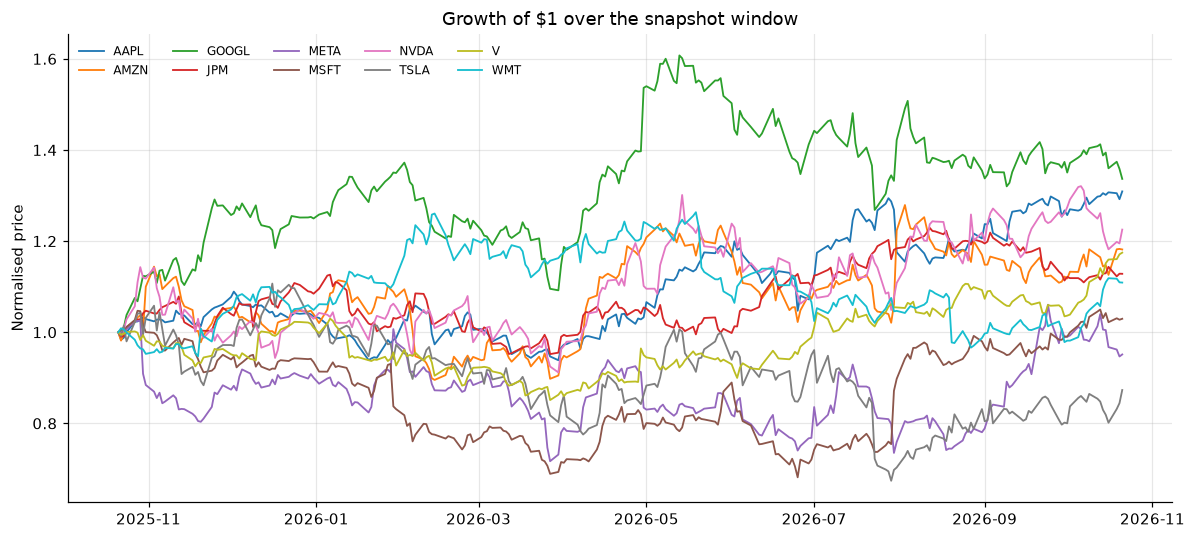

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
for ticker, g in prices.groupby("ticker"):
    ax.plot(g["date"], g["price"] / g["price"].iloc[0], label=ticker, linewidth=1.2)
ax.set_title("Growth of $1 over the snapshot window")
ax.set_ylabel("Normalised price")
ax.legend(ncol=5, fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "eda_price_paths.png")

## 3. Daily log-return distributions

Fat tails (kurtosis > 3) are expected for equities and are why the validation
suite flags outliers with a *robust* z-score (median/MAD) instead of mean/std.

In [5]:
stats = prices.groupby("ticker")["log_return"].agg(
    mean="mean", std="std", skew="skew", kurtosis=lambda s: s.kurt() + 3, min="min", max="max")
stats["annualised_vol"] = stats["std"] * np.sqrt(252)
stats["annualised_return"] = stats["mean"] * 252
stats.round(4)

,mean,std,skew,kurtosis,min,max,annualised_vol,annualised_return
ticker,,,,,,,,
AAPL,0.0011,0.0151,-0.6319,7.0084,-0.0764,0.0473,0.2405,0.2726
AMZN,0.0007,0.0215,1.4121,11.1061,-0.0572,0.1425,0.3405,0.1696
GOOGL,0.0012,0.0199,0.4481,5.7527,-0.0740,0.0950,0.3153,0.2948
JPM,0.0005,0.0139,-0.4465,4.0865,-0.0478,0.0387,0.2208,0.1226
META,-0.0002,0.0266,-0.0049,6.8853,-0.1203,0.1074,0.4222,-0.0506
MSFT,0.0001,0.0207,0.8219,14.2243,-0.1053,0.1442,0.3294,0.0296
NVDA,0.0008,0.0234,0.1663,3.5768,-0.0640,0.0838,0.3708,0.2064
TSLA,-0.0005,0.0285,-0.6028,6.2141,-0.1569,0.0812,0.4520,-0.1378
V,0.0006,0.0139,0.8028,8.4122,-0.0460,0.0794,0.2204,0.1636


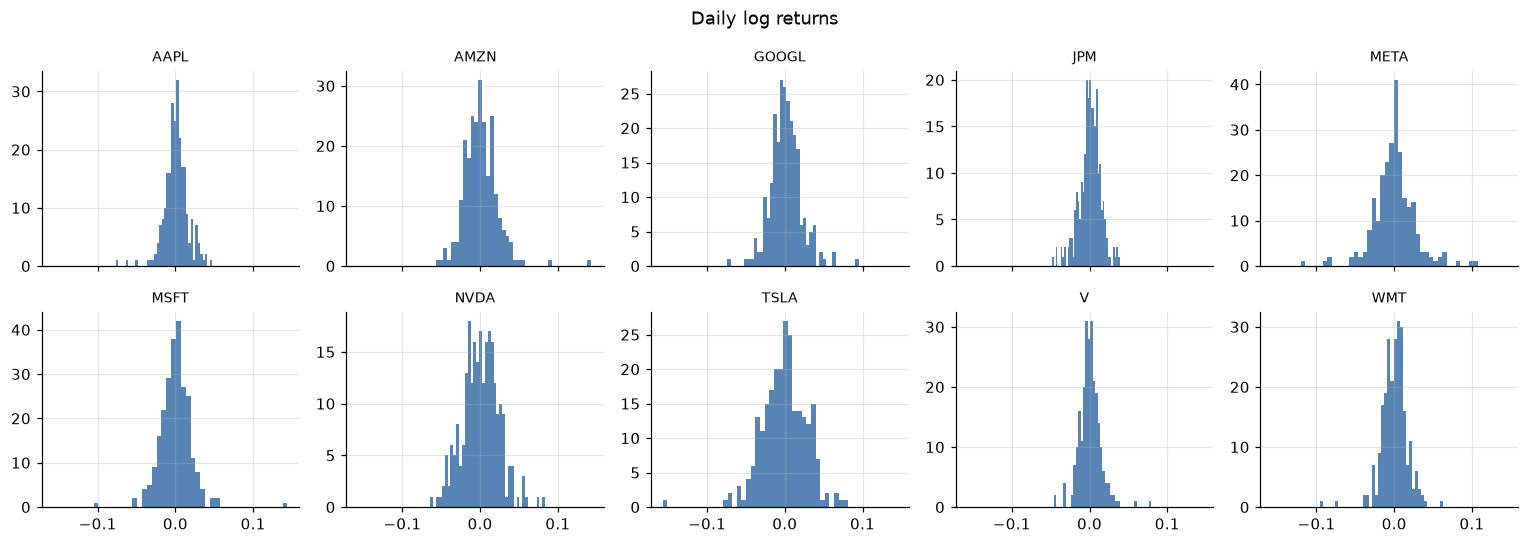

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5), sharex=True)
for ax, ticker in zip(axes.flat, TICKERS):
    r = prices.loc[prices["ticker"] == ticker, "log_return"].dropna()
    ax.hist(r, bins=40, color="#3b6ea8", alpha=0.85)
    ax.set_title(ticker, fontsize=9)
fig.suptitle("Daily log returns")
fig.tight_layout(); fig.savefig(FIG / "eda_return_hist.png")

## 4. Largest moves (outlier review)

In [7]:
top = prices.dropna(subset=["log_return"]).reindex(
    prices["log_return"].abs().sort_values(ascending=False).index).head(10)
top[["ticker", "date", "price", "log_return", "source"]]

,ticker,date,price,log_return,source
1930,TSLA,2026-07-23,319.69,-0.156931,marketstack
1437,MSFT,2026-07-30,451.10,0.144159,marketstack
441,AMZN,2026-07-31,271.58,0.142546,marketstack
1004,META,2025-10-30,666.47,-0.120302,marketstack
1224,META,2026-09-21,741.25,0.107424,marketstack
1315,MSFT,2026-01-29,433.50,-0.105284,marketstack
1065,META,2026-01-29,738.31,0.098983,marketstack
2448,WMT,2026-08-20,103.84,-0.095975,marketstack
630,GOOGL,2026-04-30,384.80,0.094962,marketstack
258,AMZN,2025-10-31,244.22,0.091526,marketstack


## 5. Correlation of daily returns

High correlation between tickers limits diversification — directly relevant to
the portfolio optimiser (Day 4).

Mean pairwise correlation: 0.157


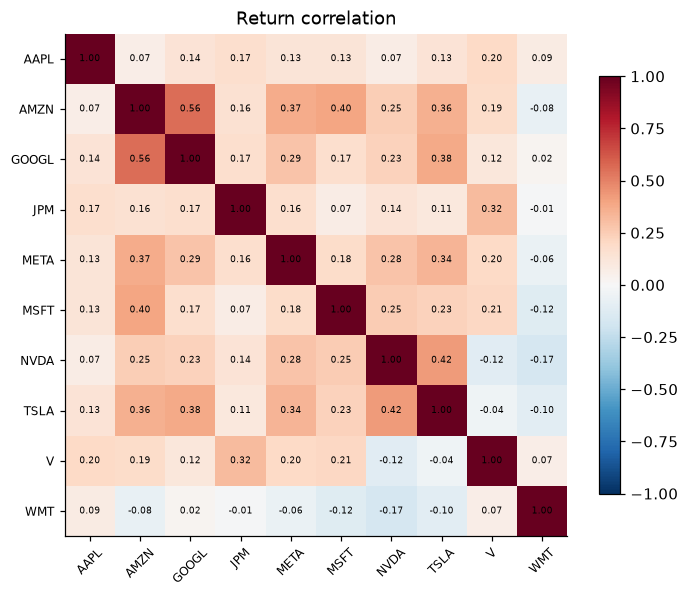

In [8]:
wide = prices.pivot(index="date", columns="ticker", values="log_return")
corr = wide.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Return correlation"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG / "eda_return_correlation.png")
print("Mean pairwise correlation:", round(corr.values[np.triu_indices(len(corr), 1)].mean(), 3))

## 6. Rolling volatility — evidence of non-stationarity

Changing volatility regimes are the data-drift the proposal's monitoring
(Day 8) must detect.

half,first_half,second_half,ratio
ticker,,,
AAPL,0.214,0.264,1.230
AMZN,0.327,0.354,1.083
GOOGL,0.286,0.343,1.200
JPM,0.243,0.197,0.808
META,0.391,0.452,1.155
MSFT,0.288,0.365,1.267
NVDA,0.358,0.385,1.074
TSLA,0.416,0.487,1.171
V,0.215,0.223,1.037


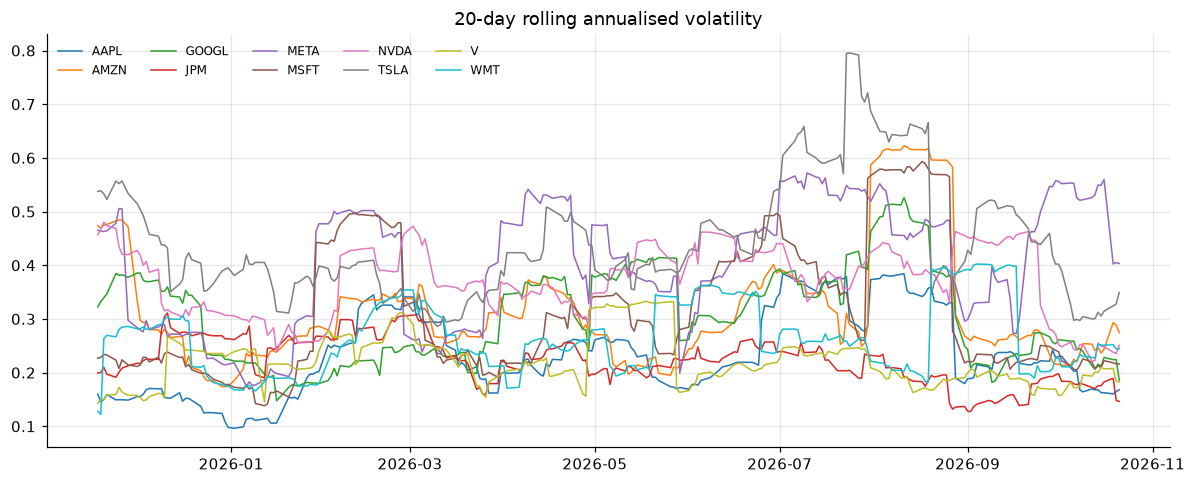

In [9]:
prices["vol_20"] = prices.groupby("ticker")["log_return"].transform(
    lambda s: s.rolling(20).std() * np.sqrt(252))
fig, ax = plt.subplots(figsize=(11, 4.5))
for ticker, g in prices.groupby("ticker"):
    ax.plot(g["date"], g["vol_20"], linewidth=1, label=ticker)
ax.set_title("20-day rolling annualised volatility"); ax.legend(ncol=5, fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "eda_rolling_volatility.png")
half = prices["date"].min() + (prices["date"].max() - prices["date"].min()) / 2
drift = prices.assign(half=np.where(prices["date"] < half, "first_half", "second_half")).groupby(
    ["ticker", "half"])["log_return"].std().unstack() * np.sqrt(252)
drift["ratio"] = drift["second_half"] / drift["first_half"]
drift.round(3)

## 7. Trading volume

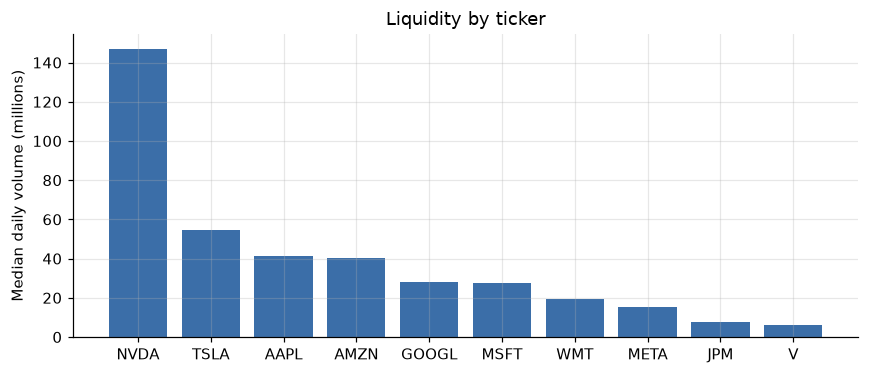

In [10]:
vol = prices.groupby("ticker")["volume"].median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(vol.index, vol.values / 1e6, color="#3b6ea8")
ax.set_ylabel("Median daily volume (millions)"); ax.set_title("Liquidity by ticker")
fig.tight_layout(); fig.savefig(FIG / "eda_volume.png")

## 8. News coverage

        mean   min   max
ticker                  
AAPL    40.0  15.0  60.0
AMZN    40.0   0.0  73.0
GOOGL   40.0   0.0  71.0
JPM     39.8  18.0  61.0
META    40.0   0.0  68.0
MSFT    40.1   0.0  66.0
NVDA    40.3   0.0  87.0
TSLA    40.1  20.0  74.0
V       38.9  14.0  58.0
WMT     39.2  20.0  60.0


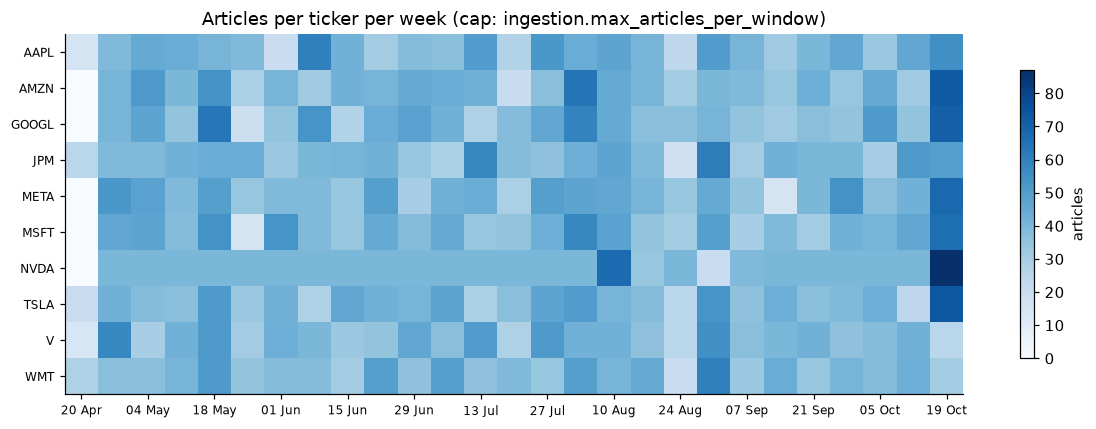

In [11]:
news["published_at"] = pd.to_datetime(news["published_at"], utc=True)
news["week"] = (news["published_at"].dt.tz_localize(None).dt.to_period("W-SUN").dt.start_time)
weekly = news.groupby(["week", "ticker"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(weekly.T, aspect="auto", cmap="Blues", vmin=0, vmax=max(1, weekly.values.max()))
fig.colorbar(im, ax=ax, shrink=0.8, label="articles")
ax.set_yticks(range(len(weekly.columns)), weekly.columns, fontsize=8)
step = max(1, len(weekly) // 10)
ax.set_xticks(range(0, len(weekly), step), [d.strftime("%d %b") for d in weekly.index[::step]],
              fontsize=8)
ax.set_title("Articles per ticker per week (cap: ingestion.max_articles_per_window)"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG / "eda_news_weekly.png")
print(weekly.describe().T[["mean", "min", "max"]].round(1))

In [12]:
print("Top sources:")
print(news["source"].value_counts().head(10).to_string())
lengths = news["text"].str.split().str.len()
print("\nWords per article text: median", int(lengths.median()), "| p95", int(lengths.quantile(0.95)))
print("Share with a summary:", round((news["summary"].fillna("").str.strip() != "").mean(), 3))

Top sources:
source
Yahoo           7577
Benzinga        1515
SeekingAlpha     767
CNBC             518
ChartMill        295
Finnhub           81
Fintel             3

Words per article text: median 36 | p95 88
Share with a summary: 0.99


## 9. Findings summary

The cell below prints the numbers to copy into `docs/DATA_CARD.md` (section *Observed
characteristics*).

In [13]:
c = coverage
print(f"- Snapshot: {prices['date'].min().date()} to {prices['date'].max().date()}, "
      f"{len(prices):,} price rows, {len(news):,} articles, {len(TICKERS)} tickers.")
print(f"- Missing trading days per ticker: min {int(c['missing_trading_days'].min())}, "
      f"max {int(c['missing_trading_days'].max())} (total {int(c['missing_trading_days'].sum())}).")
print(f"- Price provider mix: {prices['source'].value_counts().to_dict()}.")
print(f"- Annualised volatility range: {stats['annualised_vol'].min():.1%} "
      f"({stats['annualised_vol'].idxmin()}) to {stats['annualised_vol'].max():.1%} "
      f"({stats['annualised_vol'].idxmax()}).")
print(f"- Return kurtosis range: {stats['kurtosis'].min():.1f} to {stats['kurtosis'].max():.1f} "
      "(normal distribution = 3; above 3 means fat tails).")
print(f"- Mean pairwise return correlation: {corr.values[np.triu_indices(len(corr), 1)].mean():.2f}.")
print(f"- Largest daily move: {top.iloc[0]['ticker']} {top.iloc[0]['log_return']:+.1%} "
      f"on {top.iloc[0]['date'].date()}.")
print(f"- Volatility regime shift (2nd half / 1st half): {drift['ratio'].min():.2f}x to "
      f"{drift['ratio'].max():.2f}x.")
print(f"- News: {weekly.values.mean():.1f} articles per ticker-week on average; "
      f"{news['source'].nunique()} distinct sources.")

- Snapshot: 2025-10-21 to 2026-10-21, 2,492 price rows, 10,756 articles, 10 tickers.
- Missing trading days per ticker: min 2, max 3 (total 28).
- Price provider mix: {'marketstack': 2489, 'yfinance': 3}.
- Annualised volatility range: 22.0% (V) to 45.2% (TSLA).
- Return kurtosis range: 3.6 to 14.2 (normal distribution = 3; above 3 means fat tails).
- Mean pairwise return correlation: 0.16.
- Largest daily move: TSLA -15.7% on 2026-07-23.
- Volatility regime shift (2nd half / 1st half): 0.81x to 1.27x.
- News: 39.8 articles per ticker-week on average; 7 distinct sources.
